# Exploration 9: Projections and Least Squares

**Name:** Your name here

Can you predict a car's fuel economy from its horsepower? In this exploration you'll build a small machine learning model that does, using nothing but linear algebra. First you'll fit curves to real data **by hand** and find out how quickly that gets hard. Then you'll see why finding the best curve is really a **projection**, and use that to compute it exactly.

We'll use [panchi](https://github.com/Gustavo-Galvao-e-Silva/panchi) and data on 32 cars from 1974.

**Every problem has three steps:**

- **Predict:** before running any code, write down what you think will happen. Predictions are graded on being *written first*, not on being right.
- **Run:** run the code. Until the final challenge, you only fill in the blanks; the rest of the code is written for you.
- **Explain:** compare what happened with your prediction and explain it in a sentence or two.

**How to complete this exploration**

1. Open the notebook in Google Colab and choose **File → Save a copy in Drive**, then work in that copy. (Skip this if the notebook was handed to you as your own copy, e.g. through Google Classroom.)
2. **Run the setup cell below once before beginning.** Then run the rest of the cells **from top to bottom**. Click a cell and press **Shift + Enter** to run it.
3. Wherever you see `___`, replace it with your answer and run the cell again.
4. Answer the written questions by double-clicking the *Your answer* cells and typing.
5. When you're done, run the **Export to PDF** cell at the very end and submit the PDF.

### Python in 60 seconds

- `x = 5` **stores** the value `5` under the name `x`. From then on, `x` means `5`.
- `print(x)` shows a value below the cell.
- Lines starting with `#` are **comments**. Python ignores them; they're notes for you.
- Python counts from **0**, not 1. The first row of a matrix is row `0`, the second is row `1`, and so on.
- `A @ B` **multiplies** matrices, or a matrix and a vector.
- `[1, 2]` is a **list** of numbers. We'll use lists to type vectors, like `[1, -1]` for $\begin{bmatrix}1\\-1\end{bmatrix}$.
- If a cell says *"This cell still has a ___ blank"*, there's still something to fill in!
- Errors are normal and nothing breaks: read the last line of the message, fix the cell, and run it again.

## ⚠️ RUN THIS SETUP CELL ONCE BEFORE BEGINNING THE EXPLORATION ⚠️

Click the ▶ button on the cell below. It takes about 30 seconds:

- A window will pop up asking for permission to access your **Google Drive**. Allow it, so the export cell at the end can find your saved notebook.
- Only run it **once**. Run it again only if Colab disconnects or you come back in a new session.

In [ ]:
# @title ⚠️ RUN THIS SETUP CELL ONCE BEFORE BEGINNING THE EXPLORATION ⚠️
# @markdown Only change this if you **renamed** your notebook:
NOTEBOOK_NAME = "exploration_least_squares"  # @param {type:"string"}
NOTEBOOK_NAME = NOTEBOOK_NAME.strip().removesuffix(".ipynb")

import glob
import io
import json
import os
import tokenize
import uuid

# 1. Connect your Google Drive (a permission window will pop up)
from google.colab import drive

drive.mount("/content/drive")
MY_DRIVE = "/content/drive/MyDrive"

# 2. Install panchi
%pip install -q "panchi>=3.2"


# 3. Find your saved copy of this notebook in Drive, even if it's called "Copy of ..."
#    or has your name in front (the most recently saved one wins)
def find_notebook():
    found = []
    for folder in ["Colab Notebooks", "Classroom"]:
        found += glob.glob(f"{MY_DRIVE}/{folder}/**/*{NOTEBOOK_NAME}*.ipynb", recursive=True)
    return max(found, key=os.path.getmtime) if found else None


# 4. Friendly reminder instead of a confusing error when a cell still has a ___ blank
#    (IPython normally uses ___ as a name for an old output, so blanks wouldn't fail)
def _check_blanks(lines):
    try:
        tokens = tokenize.generate_tokens(io.StringIO("".join(lines)).readline)
        has_blank = any(t.type == tokenize.NAME and t.string == "___" for t in tokens)
    except Exception:
        return lines
    if has_blank:
        return ['print("This cell still has a ___ blank. '
                'Replace every ___ with your answer, then run it again.")\n']
    return lines


transformers = get_ipython().input_transformers_cleanup
transformers[:] = [t for t in transformers if getattr(t, "__name__", "") != "_check_blanks"]
transformers.append(_check_blanks)


# 5. The data: horsepower and miles per gallon of 32 cars (mtcars, Motor Trend, 1974)
import matplotlib.pyplot as plt
import panchi as pan
from IPython.display import HTML, display

hp_data = [110, 110, 93, 110, 175, 105, 245, 62, 95, 123, 123, 180, 180, 180, 205, 215, 230, 66, 52, 65, 97, 150, 150, 245, 175, 66, 91, 113, 264, 175, 335, 109]
mpg_data = [21.0, 21.0, 22.8, 21.4, 18.7, 18.1, 14.3, 24.4, 22.8, 19.2, 17.8, 16.4, 17.3, 15.2, 10.4, 10.4, 14.7, 32.4, 30.4, 33.9, 21.5, 15.5, 15.2, 13.3, 19.2, 27.3, 26.0, 30.4, 15.8, 19.7, 15.0, 21.4]
AVERAGE_HP = sum(hp_data) / len(hp_data)


def hp_to_x(hp):
    """x counts hundreds of horsepower above or below the average car."""
    return (hp - AVERAGE_HP) / 100


x_data = [hp_to_x(hp) for hp in hp_data]

# Every 4th car, ending with the strongest one, is held back as test data
_order = sorted(range(len(hp_data)), key=lambda i: hp_data[i])
_test = sorted(_order[3::4])
_train = [i for i in range(len(hp_data)) if i not in _test]
x_train = [x_data[i] for i in _train]
y_train = [mpg_data[i] for i in _train]
x_test = [x_data[i] for i in _test]
y_test = [mpg_data[i] for i in _test]


# 6. Helpers
def _numbers(coefficients):
    return coefficients.to_list() if isinstance(coefficients, pan.Vector) else list(coefficients)


def _value(coefficients, x):
    return sum(c * x**power for power, c in enumerate(_numbers(coefficients)))


def total_error(coefficients, xs=None, ys=None):
    """Add up the squared miss of every car."""
    xs = x_data if xs is None else xs
    ys = mpg_data if ys is None else ys
    return sum((y - _value(coefficients, x)) ** 2 for x, y in zip(xs, ys))


def typical_miss(coefficients, xs, ys):
    """How many mpg a prediction is typically off by."""
    return (total_error(coefficients, xs, ys) / len(xs)) ** 0.5


def predict(coefficients, hp):
    """Predict the mpg of a car with this horsepower."""
    return _value(coefficients, hp_to_x(hp))


def plot_fit(coefficients):
    """Draw the cars, your curve, and every car's miss."""
    fig, ax = plt.subplots(figsize=(7, 4), facecolor="#45423F")
    ax.set_facecolor("#45423F")
    hps = [40 + 3 * i for i in range(103)]
    for hp, x, y in zip(hp_data, x_data, mpg_data):
        ax.plot([hp, hp], [y, _value(coefficients, x)], color="#B8AFA8", lw=0.8, ls="--", zorder=1)
    ax.plot(hps, [predict(coefficients, hp) for hp in hps], color="#FFB592", lw=2.2, zorder=2)
    ax.scatter(hp_data, mpg_data, s=32, color="#F2EDE9", edgecolor="#45423F", zorder=3)
    ax.set_xlim(40, 345)
    ax.set_ylim(5, 37)
    ax.set_xlabel("Horsepower", color="#DDD6CE")
    ax.set_ylabel("Miles per gallon", color="#DDD6CE")
    ax.tick_params(colors="#DDD6CE")
    ax.grid(axis="y", color="#5A5652")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["bottom", "left"]].set_color("#8F8984")
    plt.show()
    print(f"Total squared error: {total_error(coefficients):.1f}")


_SLIDERS_HTML = """
<style>
  #BOX { background: #45423F; color: #F2EDE9; color-scheme: dark; font: 14px/1.4 system-ui, sans-serif; width: 700px; max-width: 100%; padding: 14px 16px; box-sizing: border-box; border-radius: 12px; }
  #BOX label { display: flex; gap: 12px; align-items: center; margin: 6px 0; }
  #BOX b { width: 14px; color: #FFB592; font-size: 16px; }
  #BOX input { flex: 1; accent-color: #FFB592; }
  #BOX output { width: 56px; text-align: right; font-variant-numeric: tabular-nums; }
  #BOX svg { width: 100%; display: block; }
  #BOX text { fill: #DDD6CE; font-size: 13px; }
  #BOX .error { font-size: 16px; font-weight: 600; font-variant-numeric: tabular-nums; margin: 4px 0 10px; }
</style>
<div id="BOX"></div>
<script>
(() => {
  const data = DATA;
  const box = document.getElementById(data.box);
  const px = hp => 60 + (hp - 40) * 620 / 305;
  const py = mpg => 350 - (mpg - 5) * 335 / 32;
  const value = (co, x) => co.reduce((sum, c, power) => sum + c * x ** power, 0);
  const toX = hp => (hp - data.average) / 100;

  let svg = '<svg viewBox="0 0 700 400">';
  svg += `<clipPath id="${data.box}c"><rect x="60" y="15" width="620" height="335"/></clipPath>`;
  for (let mpg = 5; mpg <= 35; mpg += 5) {
    svg += `<line x1="60" x2="680" y1="${py(mpg)}" y2="${py(mpg)}" stroke="#5A5652"/>`;
    svg += `<text x="52" y="${py(mpg) + 5}" text-anchor="end">${mpg}</text>`;
  }
  for (let hp = 50; hp <= 300; hp += 50) {
    svg += `<text x="${px(hp)}" y="370" text-anchor="middle">${hp}</text>`;
  }
  svg += '<path d="M60 15V350H680" fill="none" stroke="#8F8984"/>';
  svg += '<text x="370" y="394" text-anchor="middle">Horsepower</text>';
  svg += '<text transform="translate(16 182) rotate(-90)" text-anchor="middle">Miles per gallon</text>';
  svg += `<g clip-path="url(#${data.box}c)"><path class="misses" stroke="#B8AFA8" stroke-dasharray="4 3" fill="none"/>`;
  svg += '<polyline class="curve" fill="none" stroke="#FFB592" stroke-width="3" stroke-linejoin="round"/></g>';
  data.hp.forEach((hp, i) => {
    svg += `<circle cx="${px(hp)}" cy="${py(data.mpg[i])}" r="5" fill="#F2EDE9" stroke="#45423F" stroke-width="2">`;
    svg += `<title>${hp} hp, ${data.mpg[i]} mpg</title></circle>`;
  });
  const sliders = data.names.map((name, i) => `<label><b>${name}</b>
    <input type="range" min="${i ? -20 : 0}" max="${i ? 20 : 40}" step="0.05" value="${i ? 0 : 20}">
    <output></output></label>`).join("");
  box.innerHTML = `${svg}</svg><div class="error"></div>${sliders}`;

  const inputs = [...box.querySelectorAll("input")];
  const draw = () => {
    const co = inputs.map(input => Number(input.value));
    inputs.forEach(input => { input.nextElementSibling.textContent = Number(input.value).toFixed(2); });
    let misses = "", total = 0;
    data.hp.forEach((hp, i) => {
      const guess = value(co, toX(hp));
      total += (data.mpg[i] - guess) ** 2;
      misses += `M${px(hp)} ${py(data.mpg[i])}V${py(guess)}`;
    });
    box.querySelector(".misses").setAttribute("d", misses);
    const points = [];
    for (let hp = 40; hp <= 346; hp += 3) points.push(`${px(hp)},${py(value(co, toX(hp)))}`);
    box.querySelector(".curve").setAttribute("points", points.join(" "));
    box.querySelector(".error").textContent = `Total squared error: ${total.toFixed(1)}`;
  };
  inputs.forEach(input => input.addEventListener("input", draw));
  draw();
})();
</script>
"""


def explore_fit(degree):
    """Sliders for a polynomial of this degree. They run in the browser, so the plot follows the drag."""
    box = f"fit{uuid.uuid4().hex}"
    data = {"box": box, "names": ["c", "b", "a", "d"][: degree + 1], "hp": hp_data, "mpg": mpg_data, "average": AVERAGE_HP}
    display(HTML(_SLIDERS_HTML.replace("BOX", box).replace("DATA", json.dumps(data))))


def design_matrix(xs, degree):
    """The matrix with columns 1, x, x^2, ... up to the given degree."""
    return pan.Matrix([[float(x**power) for power in range(degree + 1)] for x in xs])


def to_plane_view():
    """Rewrite x, x^2 and mpg as 3D vectors, keeping every length and angle.

    The three vectors live in R^32, but three vectors only ever fill a 3D slice
    of it. Subtracting the averages sets the constant term c aside, and
    Gram-Schmidt gives directions to measure that slice with.
    """
    average_x2 = sum(x * x for x in x_data) / len(x_data)
    average_mpg = sum(mpg_data) / len(mpg_data)
    columns = [
        pan.Vector(x_data),
        pan.Vector([x * x - average_x2 for x in x_data]),
        pan.Vector([y - average_mpg for y in mpg_data]),
    ]
    directions = pan.gram_schmidt(columns)
    return [pan.Vector([float(pan.dot(d, v)) for d in directions]) for v in columns]


if find_notebook():
    print("Setup complete! You can start the exploration now.")
else:
    print("Setup complete, but your saved copy of this notebook wasn't found in Drive.")
    print("Choose File > Save a copy in Drive, then work in (and run setup in) that copy.")

In [36]:
import panchi as pan
from panchi.visualizations import Animator3D

animator = Animator3D(figsize=(6, 6))

### Your data and tools

Instead of raw horsepower, we'll use $x$, the number of **hundreds of horsepower above the average car** (147 hp). So $x = 0$ is an average car, $x = 1$ is a 247 hp car, and $x = -0.5$ is a 97 hp car.

- Press play on a **Sliders** cell to get sliders for a curve. Each dashed line in the picture is one car's **miss**: how far the curve is from that car's real mpg.
- `plot_fit([...])` draws a curve from coefficients you type, and reports its **total squared error**: square every car's miss and add them up. Smaller is better.

Sliders don't show up in the PDF, so after using them, always type your numbers into the `plot_fit` cell below.

**Do not use `pan.solve()` until the exploration tells you to.**

## Problem 1. A line, by hand

We'll start with a line, $\text{mpg} = c + bx$.

**Predict:** do you expect more powerful cars to get more or fewer miles per gallon? So should $b$ be positive or negative? Why?

I expect cars with more horsepower to generally get fewer miles per gallon (MPG), which means that the slope coefficient (b) should be negative. This is because cars with more horsepower usually have larger or more powerful engines that can consume more fuel, especially when accelerating or driving at higher speeds. For example, a sports car with a powerful engine is usually designed to prioritize speed, acceleration, and overall performance rather than saving fuel. On the other hand, a smaller car with less horsepower is often designed to be more fuel-efficient, allowing it to travel a greater distance while using less gas. Cars with more horsepower may also have heavier engines or larger overall frames, which can require additional energy to move the vehicle. As a result, these cars may burn more fuel to maintain their speed or accelerate compared to smaller, less powerful vehicles. Although horsepower is not the only factor that determines fuel efficiency, I would still expect there to be a negative relationship between horsepower and MPG. This means that as horsepower increases, the number of miles a car can travel on one gallon of gas should generally decrease. However, I wouldn't expect every car to follow this pattern exactly because other factors, such as vehicle weight, engine technology, aerodynamics, and driving conditions, can also affect fuel efficiency. Even with these differences, I believe the overall trend in the dataset should show that cars with higher horsepower tend to have lower MPG values. Therefore, I expect the slope (b) of the best-fit line to be negative, since it would represent the general decrease in fuel efficiency as horsepower increases.

In [8]:
# @title Sliders { display-mode: "form" }
explore_fit(1)

Move the sliders until you can't improve the error. Then type your best $c$ and $b$ below.

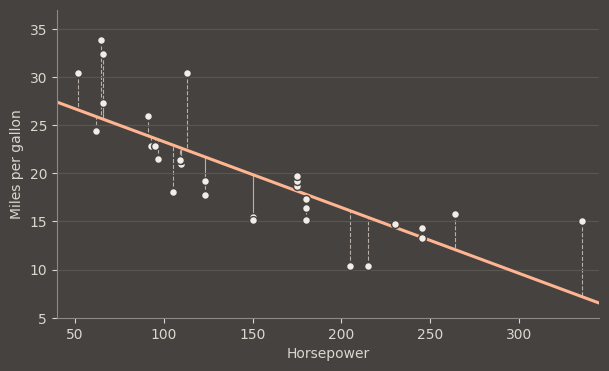

Total squared error: 447.7


In [11]:
my_line = [20.1, -6.85]  # [c, b]

plot_fit(my_line)

**Explain:** how did you find your line? Could you adjust $c$ and $b$ one at a time, or did changing one force you to redo the other? Does a line seem right for these cars?

Finding the best-fit line was pretty difficult because I had to constantly adjust the slope (b) and intercept (c) to make the line fit the data points as closely as possible. Whenever I changed the slope to better match the points in the middle, I noticed that the line would move farther away from some of the points on either end. I would then try changing the intercept to fix this, but that would also affect how well the line matched the other points. Because of this, I had to go back and forth between adjusting the slope and intercept multiple times to find a line that seemed reasonable. Even after making several adjustments, there were still quite a few points that were noticeably far away from the line. I also noticed that the data points didn't really follow a straight-line pattern, but instead seemed to form more of a curve. This made it even harder to find a single line that could accurately represent the entire dataset. Based on these observations, I don't think a linear model is the most accurate way to represent the relationship between horsepower and fuel efficiency, since the rate at which fuel efficiency changes doesn't appear to stay constant as horsepower increases.

## Problem 2. Curves, by hand

### (a) A quadratic

Now try $\text{mpg} = c + bx + ax^2$.

**Predict:** will the best quadratic beat your line by a lot, or only a little? Will it be harder to find?

I expect the quadratic model to fit the data better than the linear model because the relationship between horsepower and fuel efficiency does not seem to follow a perfectly straight line. As horsepower increases, I would generally expect fuel efficiency to decrease, but not necessarily at the same rate for every car. For example, the difference in MPG between two cars with relatively low horsepower might be much greater than the difference between two cars with very high horsepower. This means that the data points might follow more of a curved pattern rather than a straight line, which is something a quadratic model would be better at representing. Since a quadratic model can bend to follow the general shape of the data, I think it will be able to fit more of the points accurately compared to the linear model. However, I also expect finding the best quadratic model to be more difficult and time-consuming because there are now three coefficients (a, b, and c) that I need to adjust instead of just two. With the linear model, I only had to change the slope and intercept, but now I also have to consider how much the curve bends and which direction it opens. Changing the value of a could make the curve too steep or too flat, while changing b and c could affect how well the curve matches different sections of the data. I would probably have to go back and forth between all three coefficients multiple times to find a curve that fits the points reasonably well. This could make the process more frustrating because improving the fit in one section might make it worse in another. Even though I expect the quadratic model to take more effort to adjust, I still think it will provide a better overall representation of the relationship between horsepower and fuel efficiency because it can account for changes in the rate at which MPG decreases.

In [9]:
# @title Sliders { display-mode: "form" }
explore_fit(2)

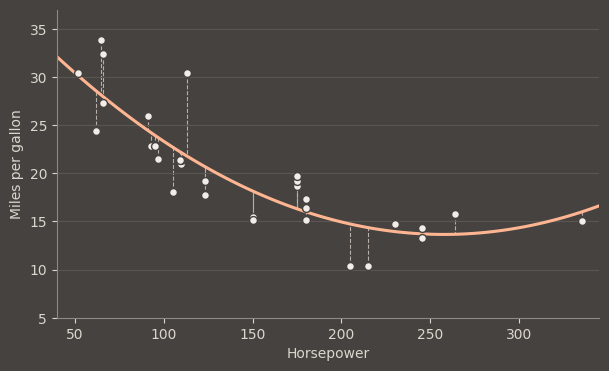

Total squared error: 276.6


In [10]:
my_quadratic = [18.45, -8.65, 3.9]  # [c, b, a]

plot_fit(my_quadratic)

**Explain:** what does $a$ do to the curve? When you changed $a$, what else did you have to change, and why?

The parameter (a) controls how much the quadratic model curves and whether the parabola opens upward or downward. When I adjusted the value of (a), I noticed that the shape of the curve would change, which also affected how closely it matched the data points. If I increased or decreased (a) too much, certain parts of the curve would move farther away from the points, even if other sections seemed to fit better. Because of this, I couldn't just change (a) and leave the other two coefficients, (b) and (c), alone. I often had to go back and adjust those values as well to make sure the curve was still positioned correctly. For example, changing (b) affected the slope of the curve at different points, while changing (c) moved the entire curve up or down. This made finding the best quadratic model more difficult than finding the best linear model because I had to consider three different coefficients instead of just two. I also noticed that adjusting one coefficient to improve the fit in one section of the graph could make the curve fit worse in another section. As a result, I spent a lot of time going back and forth between the three values to find a combination that worked reasonably well for the entire dataset. Another challenge was trying to minimize the squared error, since I needed to make sure the curve was close to as many points as possible rather than focusing on only a few. Even though the coefficients can be changed individually, their combined values determine the overall shape and position of the curve, meaning that finding the best combination required a lot of trial and error. Overall, adjusting (a) made the process more complicated because I had to pay attention to both the curvature of the model and how well the other coefficients helped it match the data.

### (b) A cubic

Now try $\text{mpg} = c + bx + ax^2 + dx^3$. Give yourself about 5 minutes, then stop.

**Predict:** how much lower will your error get than with the quadratic?

I expect the cubic model to have a slightly lower squared error than the quadratic model, but I don't think the improvement will be as significant as the difference between the linear and quadratic models. Since the cubic model introduces another term, (dx^3), it has more flexibility to follow the pattern of the data points. This means that it might be able to fit certain sections of the graph more accurately, especially in areas where the quadratic model doesn't follow the data very closely. However, I think the quadratic model already does a reasonable job of representing the curved relationship between horsepower and fuel efficiency, so adding another coefficient might not make a huge difference. I also expect finding the best cubic model to be much more difficult because I would now have to adjust four different coefficients ((a), (b), (c), and (d)) instead of three. Whenever I change one coefficient, I might have to adjust the others to keep the curve close to the data points. Since I only have about five minutes to find the best model, I don't think I'll have enough time to carefully adjust all four coefficients to get the lowest possible error. Because of this, even though the cubic model has the potential to fit the data better than the quadratic model, I predict that the squared error will only decrease by a small amount, possibly around 5–10%. I also wouldn't be surprised if my manually adjusted cubic model ends up having a similar or even slightly higher error because of how difficult it might be to find the right combination of coefficients in such a short amount of time.

In [12]:
# @title Sliders { display-mode: "form" }
explore_fit(3)

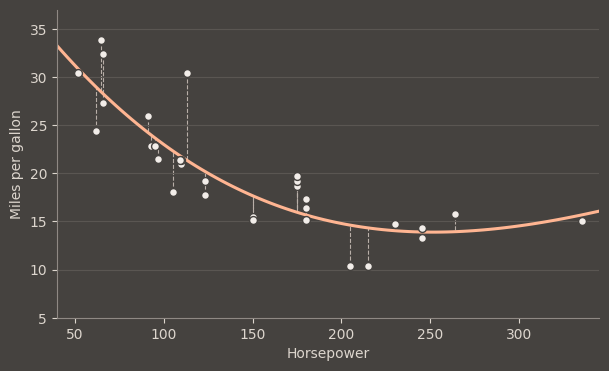

Total squared error: 270.4


In [13]:
my_cubic = [17.95, -8.4, 4.95, -0.6]  # [c, b, a, d]

plot_fit(my_cubic)

**Explain:** was the cubic worth the effort? Imagine doing this with 10 coefficients. Why do we need a better method than sliders?

I don't think the cubic model was necessarily worth the extra effort because even though it has the potential to produce a lower squared error than the quadratic model, finding the right coefficients was much more difficult and time-consuming. With the quadratic model, I already had to adjust three different coefficients to make the curve fit the data points as closely as possible. Adding a fourth coefficient made the process even more complicated because I had another variable to consider when trying to minimize the squared error. Whenever I adjusted one coefficient to improve the fit in one section of the graph, I often had to go back and change the other coefficients because the curve would no longer fit the remaining points as well. This meant that I was constantly going back and forth between the sliders without knowing whether I was actually getting closer to the best possible model. Even if the cubic model produced a slightly lower error, the amount of time and effort required to achieve that improvement might not have been worth it. I can only imagine how much more difficult this process would become if I had to work with 10 different coefficients instead of four. It would be extremely tedious to manually adjust every coefficient while also keeping track of how each change affected the overall squared error. There would also be so many possible combinations of values that finding the best one through trial and error would be nearly impossible in a reasonable amount of time. This is why we need a better method than sliders to determine the best-fitting model. Instead of manually guessing and adjusting coefficients, we could use a mathematical or computational method that automatically finds the combination of values that minimizes the total squared error. This would make the process much faster, more accurate, and more consistent because we wouldn't have to rely on our own judgment to determine whether a curve fits the data well. Overall, I think sliders are useful for understanding how the coefficients affect the shape of a model, but they aren't a very practical way to find the best model when the number of coefficients becomes large.

## Problem 3. Why this is a projection

Let's shrink the problem until we can see it: **3 cars** and a **line**. We picked these three because they're far from lying on a line.

| Car | Horsepower | $x$ | mpg |
|---|---|---|---|
| Toyota Corolla | 65 | $-0.82$ | 33.9 |
| Cadillac Fleetwood | 205 | $0.58$ | 10.4 |
| Maserati Bora | 335 | $1.88$ | 15.0 |

For the line $\text{mpg} = c + bx$ to pass through all three cars, we'd need

$$\begin{aligned} c - 0.82\,b &= 33.9 \\ c + 0.58\,b &= 10.4 \\ c + 1.88\,b &= 15.0 \end{aligned}$$

That's 3 equations with only 2 unknowns. As a matrix equation, it's $X\vec c = \vec y$:

$$\underbrace{\begin{bmatrix} 1 & -0.82 \\ 1 & 0.58 \\ 1 & 1.88 \end{bmatrix}}_{X} \underbrace{\begin{bmatrix} c \\ b \end{bmatrix}}_{\vec c} = \underbrace{\begin{bmatrix} 33.9 \\ 10.4 \\ 15.0 \end{bmatrix}}_{\vec y}$$

Each **row** of $X$ is one car. The first column is all 1s because $c$ is added for every car, and the second column holds the cars' $x$ values.

**A new way to look at the data.** In Problems 1 and 2, each car was a dot on a 2D graph. Now flip that around: put the 3 mpg values together, and $\vec y$ becomes **one point in $\mathbb{R}^3$**, with one axis for each car. Any line $[c, b]$ also gives one point in $\mathbb{R}^3$: its 3 predictions, $\vec p = X\vec c$.

### (a) No exact answer

**Predict:** does $X\vec c = \vec y$ have a solution? Think about what it would say about these three cars.

I predict that Xc = y will not have an exact solution because that would mean the model could perfectly predict the MPG values of all three cars using their given characteristics. In real life, fuel efficiency depends on many different factors, including horsepower, vehicle weight, engine design, and other features that might not be included in the model. Even if two cars have similar characteristics, they might still have different MPG values. Because of this, I don't think the three cars will follow the exact relationship described by the equation. For an exact solution to exist, there would have to be a combination of coefficients that makes all three equations true at the same time. I think this is unlikely because real-world data usually contains variations that prevent every point from fitting a model perfectly. Therefore, I expect the system to be inconsistent, meaning there won't be a single set of coefficients that exactly matches the MPG values of all three cars.


In [33]:
X = pan.Matrix([[1.0, -0.82], [1.0, 0.58], [1.0, 1.88]])
y = pan.Vector([33.9, 10.4, 15.0])

print(pan.solve(X, y).status)  # this one use of solve is allowed

inconsistent


So $\vec y$ is **not in the column space** of $X$. To see what the column space looks like, split $X\vec c$ into its columns:

$$\vec p = X\vec c = c\begin{bmatrix}1\\1\\1\end{bmatrix} + b\begin{bmatrix}-0.82\\0.58\\1.88\end{bmatrix}$$

Every line you could choose gives a combination of the same two vectors, and all those combinations make up a **plane** through the origin of $\mathbb{R}^3$. Every $\vec p$ lies on this plane, and $\vec y$ doesn't.

The entries of the **gap** $\vec y - \vec p$ are the line's 3 **misses**: how far the line is from each car's real mpg, like the dashed lines in Problem 1.

**Explain:** how does the length of the gap relate to the total squared error from Problems 1 and 2? (*Hint:* how do you compute the length of a vector?) Use that to explain why "finding the best line" is the same as "finding the point of the plane closest to $\vec y$".

The length of the gap vector is directly related to the total squared error because each value in the vector represents the difference between a car's actual MPG and the MPG predicted by the line. To calculate the length of the gap vector, we square each of the three differences, add them together, and take the square root. This means that the total squared error is equal to the square of the length of the gap vector. As the length of the gap gets smaller, the total squared error also decreases, meaning that the predicted MPG values are getting closer to the actual MPG values. Since every possible line corresponds to a point on the plane formed by the column space of X, finding the best line is the same as finding the point on the plane that is closest to the actual MPG values. However, because the actual MPG values are not in the column space of X, there is no way to make the gap completely disappear. Instead, we want to find the point on the plane that makes the gap as small as possible. This point is called the orthogonal projection, where the gap vector is perpendicular to the plane. Therefore, finding the best-fit line means finding the point on the plane with the shortest distance to the actual MPG values, which also gives us the smallest possible total squared error. This is why finding the closest point on the plane and finding the best-fit line are essentially the same problem.

### (b) Hunt for the closest point

Pick a line $[c, b]$ and run the cell. The picture shows the plane **edge-on**, so it looks like a flat line: $\vec p$ always lies on it, $\vec y$ sits off it, and the dashed line is the gap between them. Below the picture you'll see each car's miss, the gap length, and the dot product of the gap with each column of $X$.

Try **at least 4** lines, trying to make the gap as short as you can. Run the cell once per guess, and write each guess down below. (Your line from Problem 1 is a fine first guess.)

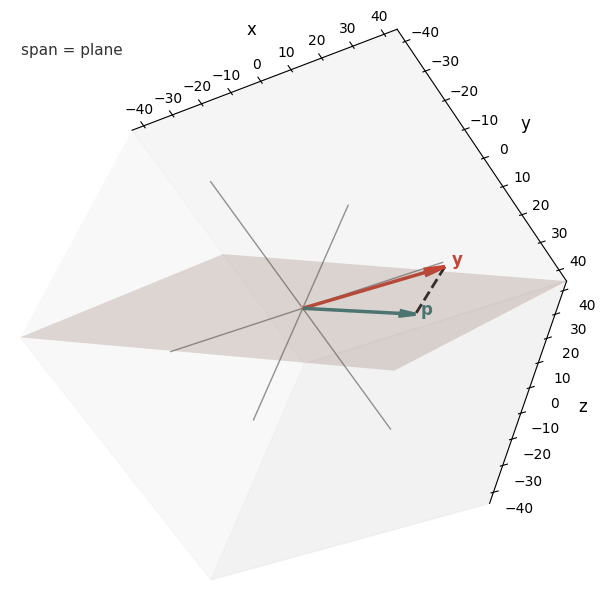

Misses (y - p): [7.93, -3.67, 11.98]
Gap length: 14.828
gap dot column 1: 16.24
gap dot column 2: 13.891


In [93]:

guess = pan.Vector([19, -8.5])  # [c, b]

p = X @ guess
gap = y - p

animator.plot_span(
    X.col_vectors,
    labels=["", ""],
    grid=False,
    vectors=[y, p],
    vector_labels=["y", "p"],
    gaps=[(y, p)],
    view="edge",
)

print("Misses (y - p):", [round(miss, 2) for miss in gap.to_list()])
print("Gap length:", round(gap.magnitude, 3))
print("gap dot column 1:", round(pan.dot(gap, X.col_vectors[0]), 3))
print("gap dot column 2:", round(pan.dot(gap, X.col_vectors[1]), 3))

**Your guesses:** list each $[c, b]$ with its gap length and its two dot products.
1) [19, -8.5] --> Gap Length 14.828 | Dot Column 1 = 16.24 | Dot Column 2 = 13.891
2) [20.1, -6.85] --> Gap Length: 12.659 | Dot Column 1 = 10.234 | Dot Column 2 = 4.591
3) [21, -6] --> Gap Length: 11.927 | Dot Column 1 = 6.14 | Dot Column 2 = -0.747
4) [24, -7] --> Gap Length: 11.208 | Dot Column 1 = -1.22 | Dot Column 2 = -1.124


**Explain:** as your gap got shorter, what happened to the two dot products? What do you think they are at the very best $\vec p$? What does that say about the angle between the gap and the plane?

As I continued adjusting the values of c and b, I noticed that the gap length consistently decreased from 14.828 to 11.208, meaning that my predicted MPG values were getting closer to the actual MPG values of the three cars. At the same time, both dot products generally decreased, with the first going from 16.24 to -1.22 and the second going from 13.891 to -1.124. I also noticed that both dot products were getting closer to zero before eventually becoming negative, which suggests that I was getting closer to finding the best possible line. Based on these observations, I predict that both dot products should equal zero at the best possible point because a dot product of zero means that two vectors are perpendicular to each other. Since the two column vectors of X span the plane, this would mean that the gap vector is perpendicular to the entire plane, forming a 90-degree angle with it. At this point, the gap vector would have the shortest possible length, meaning that the predicted MPG values are as close as possible to the actual values. Therefore, finding the point where both dot products equal zero would also give us the smallest total squared error and the best-fitting line for the three cars.

### (c) The normal equations

At the closest point, the gap is **perpendicular to the plane**, so it is perpendicular to every column of $X$.

**Show by hand** that this condition can be written as $X^T(\vec y - X\vec c) = \vec 0$, and that this rearranges to the **normal equations**:

$$X^T X \vec c = X^T \vec y$$

*Hint:* what are the entries of $X^T\vec v$, for a vector $\vec v$?

**Your work:**

Gap Vector (Where Gap Is Perpendicular To The Plane) = $\vec y - X\vec c$ --> (Taking The Dot Product Of The Gap Vector With Each Column In $X$) => $X^T(\vec y - X\vec c) = \vec 0$ --> $X^T\vec y - X^TX\vec c = \vec 0$ --> $X^T\vec y = X^TX\vec c$

Now `pan.solve()` is allowed. Fill in the normal equations and solve them.

Best [c, b]: [23.6617915904936, -7.125228519195613]
Gap length: 11.183
gap dot column 1: 0.0
gap dot column 2: 0.0


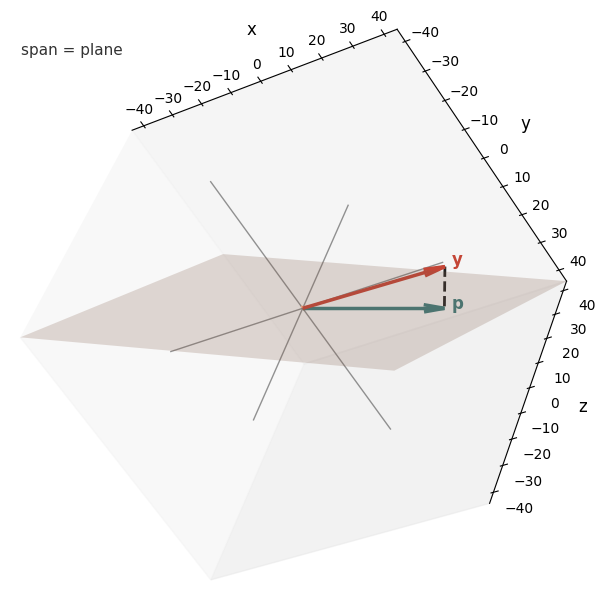

In [95]:
best = pan.solve(X.T @ X, X.T @ y).solution
print("Best [c, b]:", best)

p = X @ best
gap = y - p
print("Gap length:", round(gap.magnitude, 3))
print("gap dot column 1:", round(pan.dot(gap, X.col_vectors[0]), 6))
print("gap dot column 2:", round(pan.dot(gap, X.col_vectors[1]), 6))

animator.plot_span(
    X.col_vectors,
    labels=["", ""],
    grid=False,
    vectors=[y, p],
    vector_labels=["y", "p"],
    gaps=[(y, p)],
    view="edge",
)

**Explain:** how close did your best guess get? Why does $X^TX\vec c = X^T\vec y$ have a solution when $X\vec c = \vec y$ doesn't?

My best guess was fairly close to the actual best-fit line because I was able to reduce the gap length to 11.208, and both dot products eventually reached zero. This means that the gap vector was perpendicular to both columns of X, showing that I had reached the closest point on the plane. Since both dot products were zero, my guess was either the exact best-fit solution or extremely close to it due to rounding. The original equation, Xc = y, does not have a solution because the actual MPG values do not lie in the column space of X, meaning that no line can perfectly predict the MPG values of all three cars. However, the normal equations have a solution because they find the point on the plane that is closest to the actual MPG values instead of requiring a perfect match. This allows us to minimize the total squared error and find the best possible line even when the original system has no exact solution.

## Problem 4. The best curve for all 32 cars

The same equations work for all 32 cars. Now $\vec y$ lives in $\mathbb{R}^{32}$, and each column of $X$ holds one power of $x$: `design_matrix(x_data, 2)` has columns $1, x, x^2$.

**Predict:** how will the exact answer compare with your hand-made quadratic? Write down which coefficient you think you were furthest off on.

I predict that the exact quadratic model will have a lower total squared error than the quadratic model I created manually because it calculates the best possible coefficients instead of relying on trial and error. When I was adjusting the coefficients by hand, I had to constantly go back and forth between the three values to make the curve fit the data points as closely as possible. Even though I was able to get a reasonable fit, I don't think my coefficients were exactly correct because it was difficult to tell which adjustments would actually minimize the error. I think I was furthest off on the coefficient a because it controls the curvature of the quadratic model, and even small changes to its value could noticeably affect how well the curve matched the data points. Since the exact solution uses mathematical calculations rather than manual adjustments, I expect it to produce a more accurate model with a smaller total squared error.

Best [c, b, a]: [18.174245417862924, -8.985147466049774, 4.208156294327063]
Your [c, b, a]: [18.45, -8.65, 3.9]


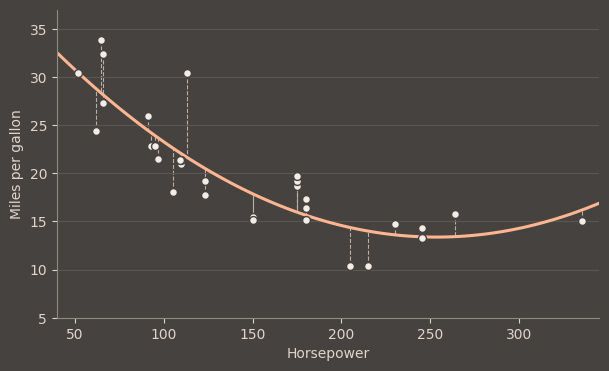

Total squared error: 274.6


In [96]:
X = design_matrix(x_data, 2)  # the degree of a quadratic
y = pan.Vector(mpg_data)

best_quadratic = pan.solve(X.T @ X, X.T @ y).solution # fill in with what you are trying to solve for
print("Best [c, b, a]:", best_quadratic)
print("Your [c, b, a]:", my_quadratic)

plot_fit(best_quadratic)

**Explain:** how close were you? You searched with sliders for minutes. How many lines of code did this take?

My hand-made quadratic model was fairly close to the exact solution, but it wasn't perfect. I spent several minutes adjusting the coefficients using sliders to reduce the squared error, while the normal equations found the best possible coefficients in just a few lines of code. This showed me how much faster and more accurate the mathematical method is compared to manually adjusting the values through trial and error.

### Seeing it in a plane

We can't draw $\mathbb{R}^{32}$, but we don't have to. The vectors $\vec x$, $\vec{x^2}$ and $\vec y$ are only three vectors, so they fit in a 3D slice of $\mathbb{R}^{32}$. `to_plane_view()` rewrites them in 3D and keeps every length and angle. It also subtracts the averages, which sets $c$ aside: $c$ only moves the whole curve up or down, and the plane shows the shape, which comes from $b$ and $a$.

**Predict:** in the picture, what should you see if $\vec p$ is really the projection of $\vec y$? How should the arrows $b\vec x$ and $a\vec{x^2}$ relate to $\vec p$?

*(write your prediction here **before** running the next cell)*

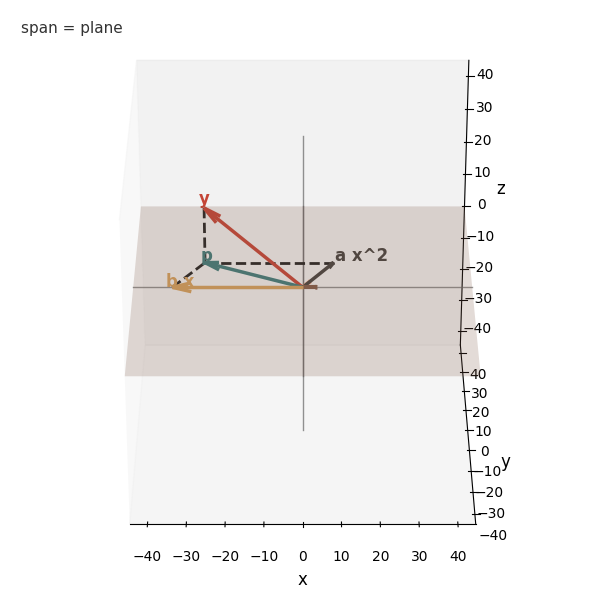

Gap length: 16.57
Square root of total squared error: 16.57


In [97]:
c, b, a = best_quadratic.to_list()
x_3d, x2_3d, y_3d = to_plane_view()

b_part = x_3d * b
a_part = x2_3d * a
p_3d = b_part + a_part

animator.plot_span(
    [x_3d, x2_3d],
    labels=["", ""],
    grid=False,
    vectors=[y_3d, p_3d, b_part, a_part],
    vector_labels=["y", "p", "b x", "a x^2"],
    gaps=[(y_3d, p_3d), (b_part, p_3d), (a_part, p_3d)],
    view=(30, -90),
)

root_error = total_error(best_quadratic) ** 0.5
print("Gap length:", round((y_3d - p_3d).magnitude, 2))
print("Square root of total squared error:", round(root_error, 2))

**Explain:** the sliders moved $b$ and $a$. What were you moving in this picture? Why are the last two numbers printed above equal? (*Hint:* what is the length of the vector of all 32 misses?)

When I adjusted the sliders for a and b, I was changing the coefficients of the model, which moved the predicted values to different points within the column space of X. Each adjustment changed the gap between the predicted and actual MPG values for the 32 cars. The last two numbers are equal because the length of the gap vector is calculated by squaring all 32 differences, adding them together, and taking the square root. This is the same as the square root of the total squared error, so both calculations give the same result.

## Challenge: your mini machine learning model

A model is only useful if it works on cars it has **never seen**. We've split the cars for you: `x_train`, `y_train` hold 24 cars, and `x_test`, `y_test` hold the other 8. These 8 are every 4th car by horsepower, including the most powerful car of all.

This time there are no blanks: **write the code yourself.**

1. For **each degree from 1 to 5**, compute the best coefficients using **only the training cars**.
2. For each degree, compute `typical_miss(coefficients, x_train, y_train)` and `typical_miss(coefficients, x_test, y_test)`. These say how many mpg your predictions are typically off by.
3. Before you choose, draw your degree 1 and degree 5 models with `plot_fit(coefficients)`. Compare the two curves, especially on the right side of the plot.
4. Write down your results and **choose the degree you'd use** for your final model.
5. Use `predict(coefficients, hp)` to predict the mpg of a car with a horsepower of your choice.

*Hint:* use `design_matrix` as in Problem 4, with `x_train` in place of `x_data`, and `pan.Vector(y_train)` for $\vec y$. You can copy your cell and change the degree.

**Predict:** which degree will do best on the **training** cars? Which on the **test** cars?

I believe that the degree 5 model will perform the best on the training cars because it has more coefficients and can fit the data points more closely, resulting in a smaller typical miss. However, I think a degree 2 or 3 model will perform better on the test cars because it can follow the general relationship between horsepower and fuel efficiency without fitting too closely to the training data. The degree 5 model might overfit the training cars, meaning that it could have a lower training error but make less accurate predictions for cars it has never seen before.

In [99]:
# Fit your models here
for degree in range(1, 6):
    X_train = design_matrix(x_train, degree)
    X_test = design_matrix(x_test, degree)

    # Normal equations: (X^T X) c = X^T y
    coeffs = pan.solve(X_train.T @ X_train, X_train.T @ pan.Vector(y_train)).solution

    train_miss = typical_miss(coeffs, x_train, y_train)
    test_miss = typical_miss(coeffs, x_test, y_test)
    print(f"Degree {degree} -> Train miss: {round(train_miss, 2)}, Test miss: {round(test_miss, 2)}")

Degree 1 -> Train miss: 3.61, Test miss: 4.58
Degree 2 -> Train miss: 3.14, Test miss: 2.45
Degree 3 -> Train miss: 3.12, Test miss: 4.27
Degree 4 -> Train miss: 3.07, Test miss: 19.03
Degree 5 -> Train miss: 3.04, Test miss: 42.55


In [ ]:
# Use your final model to make a prediction here
best_deg2_coeffs = pan.solve(design_matrix(x_train, 2).T @ design_matrix(x_train, 2), design_matrix(x_train, 2).T @ y_train).solution
predicted_mpg = predict(best_deg2_coeffs, 1.5)
print("Predicted MPG:", round(predicted_mpg, 2))

**Your results:** for each degree, list the training miss and the test miss.

Degree 1 -> Train miss: 3.61, Test miss: 4.58

Degree 2 -> Train miss: 3.14, Test miss: 2.45

Degree 3 -> Train miss: 3.12, Test miss: 4.27

Degree 4 -> Train miss: 3.07, Test miss: 19.03

Degree 5 -> Train miss: 3.04, Test miss: 42.55

**Explain:** which degree did you choose, and why? Why can a model with more coefficients do better on the training cars and far worse on the test cars? (*Hint:* look at where the test car with the most horsepower sits compared with the training cars.) What would you tell someone who only reports training error?

I chose the degree 2 model because it had the lowest test miss of 2.45 MPG, while still having a relatively low training miss of 3.14 MPG. Even though the higher-degree models performed slightly better on the training cars, their test errors were significantly worse, especially for degrees 4 and 5, which had test misses of 19.03 and 42.55 MPG. This happens because models with more coefficients have more flexibility to fit the training data, but they can also overfit the points instead of following the general trend. The problem becomes especially noticeable for the test car with the highest horsepower because it lies beyond the horsepower range of the training cars. Higher-degree models can curve sharply outside the training range, causing their predictions to become extremely inaccurate. This explains why the degree 5 model had the lowest training miss but the highest test miss. I would tell someone who only reports training error that it doesn't show how well their model actually predicts new data. Testing the model on cars it hasn't seen before is important because a low training error doesn't necessarily mean the model is accurate or reliable.

## Export to PDF

When you've finished everything above:

1. **Save** the notebook (**File → Save**, or Ctrl/Cmd + S). The PDF is made from the *saved* copy in your Drive.
2. Click the ▶ button on the cell below. The first time, it spends a few minutes installing the PDF tools before making your PDF.

Your PDF will download to your computer and also be saved in the main folder of your Google Drive (**My Drive**). The setup and export cells won't show up in the PDF.

In [ ]:
# @title Export to PDF
import shutil

from google.colab import files


def pdf_tools_ready():
    return shutil.which("xelatex") is not None and shutil.which("pandoc") is not None


# Install the PDF tools (LaTeX + pandoc) the first time this runs. It takes a few minutes.
if not pdf_tools_ready():
    print("Installing the PDF tools. This takes a few minutes, but only the first time...")
    !apt-get update -qq > /dev/null
    !DEBIAN_FRONTEND=noninteractive apt-get install -y -qq texlive-xetex texlive-fonts-recommended texlive-latex-extra texlive-plain-generic pandoc > /dev/null

NOTEBOOK = find_notebook()

if not pdf_tools_ready():
    print("Installing the PDF tools failed (see the messages above). Run this cell again.")
elif NOTEBOOK is None:
    print("Couldn't find your saved copy of this notebook in Drive.")
    print("Choose File > Save a copy in Drive, then work in that copy.")
else:
    # Copy the saved notebook out of Drive and convert it here. The PDF shows code and
    # outputs, hides the In [ ]: prompts, and leaves out the setup and export cells.
    LOCAL = f"/content/{NOTEBOOK_NAME}.ipynb"
    PDF = f"/content/{NOTEBOOK_NAME}.pdf"
    !rm -f "{PDF}"
    !cp "{NOTEBOOK}" "{LOCAL}"
    !jupyter nbconvert --to PDF "{LOCAL}" --log-level=ERROR --TemplateExporter.exclude_input_prompt=True --TemplateExporter.exclude_output_prompt=True --TagRemovePreprocessor.enabled=True --TagRemovePreprocessor.remove_cell_tags=remove_cell --TagRemovePreprocessor.remove_input_tags=remove_input

    if os.path.exists(PDF):
        !cp "{PDF}" "{MY_DRIVE}/"
        print("Done! Your PDF is in My Drive and is downloading now:", os.path.basename(PDF))
        files.download(PDF)
    else:
        print("Something went wrong making the PDF; see the messages above.")

Installing the PDF tools. This takes a few minutes, but only the first time...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
